# Touching nuclei: thresholding, markers and watershed

**M2 practical — 20 minutes** · Python · scikit-image · ipywidgets

**Goal:** Understand why **one connected region is not necessarily one nucleus**, and how changing parameters can improve or degrade segmentation.

| Step | Time | What you do |
|---|---:|---|
| **1. Count by eye** | 3 min | Record your own estimate before discussing it |
| **2. Binary segmentation** | 8 min | Change only Gaussian **σ** and **threshold** |
| **3. Marker-controlled watershed** | 9 min | Change only **min_distance** and **peak_height** |

**Instructions:** Run the setup cells, then follow the questions in order. Write your answers directly in the editable **Answer** code cells; these answers remain in the notebook when you save it. No external image is required. If you have the original `CD34_blue_crop.png` file, place it beside the notebook and it will be used instead of the built-in reference image.


## Setup — run the next two cells once

The bundled image is recovered approximately from the **displayed figure saved in the original notebook**, not from the original microscopy pixels. This makes the notebook self-contained but may slightly change threshold-dependent counts. For image measurement or a publication, use the original image file.

If an import fails, run `%pip install numpy scipy matplotlib scikit-image ipywidgets pillow`, then restart the kernel.

In [1]:
# Bundled teaching image — no edits needed (approximately reconstructed from the notebook figure).
import base64
import io
from pathlib import Path
import numpy as np
from PIL import Image

_REFERENCE_PNG_B64 = (
    '...'
)

def load_reference_image():
    original = Path('CD34_blue_crop.png')
    if original.exists():
        with Image.open(original) as pil:
            image = np.asarray(pil.convert('L'), dtype=np.float32)
        # If a 16-bit raw file is used, adapt the intensity scaling explicitly.
        return image, 'Original image from CD34_blue_crop.png'
    with Image.open(io.BytesIO(base64.b64decode(_REFERENCE_PNG_B64))) as pil:
        image = np.asarray(pil.convert('L'), dtype=np.float32)
    return image, 'Bundled approximate image from the notebook preview'

image, image_source = load_reference_image()
print(image_source)
print(f'Image shape: {image.shape} | intensity range: {image.min():.0f}–{image.max():.0f} / 255')


Bundled approximate image from the notebook preview
Image shape: (187, 240) | intensity range: 0–246 / 255


In [2]:
# Processing functions — run once; you do not need to modify them.
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from scipy import ndimage as ndi
from skimage.filters import gaussian
from skimage.feature import peak_local_max
from skimage.measure import label
from skimage.segmentation import watershed, find_boundaries

try:  # Required for sliders in Google Colab
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
except ImportError:
    pass


def binary_mask(image, sigma, threshold):
    """Binary mask controlled by only TWO tunable parameters.

    sigma: Gaussian blur radius in pixels; 0 means no smoothing.
    threshold: intensity cutoff on the 0–255 image.
    """
    smoothed = gaussian(image, sigma=float(sigma), preserve_range=True)
    mask = smoothed > float(threshold)
    return smoothed, mask


def mask_statistics(mask):
    cc = label(mask, connectivity=2)  # 8-connected components in 2D
    areas = np.bincount(cc.ravel())[1:]
    return {'components': int(cc.max()),
            'tiny_components': int(np.sum(areas < 10)),
            'connected_labels': cc}


def markers_and_watershed(mask, min_distance, peak_height):
    """Marker detection using only TWO tunable parameters.

    min_distance: minimum peak separation in pixels.
    peak_height: minimum Euclidean-distance peak height in pixels.
                 (Not an intensity threshold!)
    """
    distance = ndi.distance_transform_edt(mask)
    peaks = peak_local_max(distance, labels=mask,
                           min_distance=int(min_distance),
                           threshold_abs=float(peak_height),
                           exclude_border=False)
    markers = np.zeros(mask.shape, dtype=np.int32)
    if len(peaks):
        markers[peaks[:, 0], peaks[:, 1]] = np.arange(1, len(peaks) + 1)
    regions = watershed(-distance, markers=markers, mask=mask)
    return distance, peaks, markers, regions

print('Functions ready.')

Functions ready.


## 1 — How many nuclei do you see? (3 min)

**Before running any segmentation:** count the nuclei by eye, including dim ones. If your teacher uses Wooclap, submit the same estimate there first.


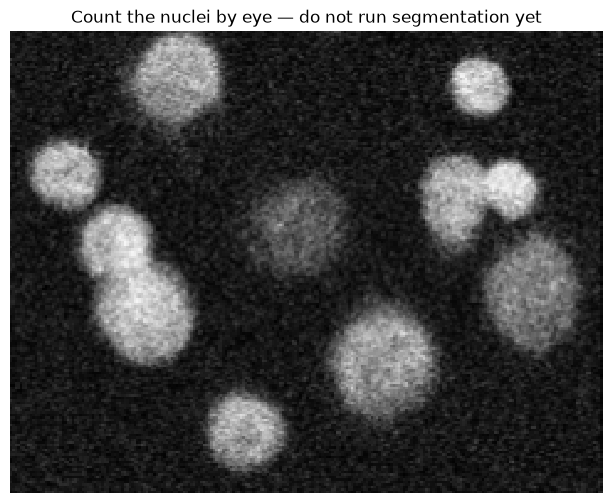

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
ax.set_title('Count the nuclei by eye — do not run segmentation yet')
ax.axis('off')
plt.show()

In [4]:
# ANSWER 1 — edit the two lines, then run this cell.
my_visual_count = None    # Replace None with your estimated number
hardest_nuclei_to_count = ""  # e.g., "the dim nucleus near the centre"

answers = {'visual_count': my_visual_count,
           'difficult_nuclei': hardest_nuclei_to_count}
print('Your estimate:', answers['visual_count'])
print('Uncertain area:', answers['difficult_nuclei'])

Your estimate: None
Uncertain area: 


## 2 — How do σ and threshold change the binary mask? (8 min)

The binary mask is computed from just **two parameters**:

```python
smoothed, mask = binary_mask(image, sigma, threshold)
```

**Gaussian σ (pixels)** controls smoothing; **threshold (image intensity)** decides which pixels become white. Connected-component counting labels each continuous white region, **not necessarily each nucleus**. Small noisy regions can be false detections; touching nuclei can be counted as only one region.

Move the two sliders below. The output reports the **total number of connected components** and how many are **tiny (fewer than 10 pixels)**. The latter is a simple diagnostic, not an automatic quality criterion.

In [5]:
def explore_binary(image, sigma=2.0, threshold=50):
    """Exactly two controls: smoothing and threshold."""
    sigma_slider = widgets.FloatSlider(value=sigma, min=0, max=7, step=0.5,
                                       description='Gaussian σ (px)',
                                       continuous_update=False,
                                       style={'description_width':'initial'},
                                       layout=widgets.Layout(width='480px'))
    threshold_slider = widgets.IntSlider(value=threshold, min=10, max=160, step=5,
                                        description='Threshold (0–255)',
                                        continuous_update=False,
                                        style={'description_width':'initial'},
                                        layout=widgets.Layout(width='480px'))

    def update(sigma, threshold):
        smooth, mask = binary_mask(image, sigma, threshold)
        stats = mask_statistics(mask)
        fig, ax = plt.subplots(2, 2, figsize=(10.5, 7.2), constrained_layout=True)
        ax[0,0].imshow(image, cmap='gray', vmin=0, vmax=255)
        ax[0,0].set_title('Original')
        ax[0,1].imshow(smooth, cmap='gray', vmin=0, vmax=255)
        ax[0,1].set_title(f'Gaussian σ = {sigma:g} px')
        ax[1,0].imshow(mask, cmap='gray', vmin=0, vmax=1)
        ax[1,0].set_title(f'Binary mask: {stats["components"]} connected objects')
        ax[1,1].imshow(image, cmap='gray', vmin=0, vmax=255)
        ax[1,1].contour(mask.astype(float), levels=[0.5], colors='orange', linewidths=0.8)
        ax[1,1].set_title('Binary-mask borders on original')
        for a in ax.flat:
            a.axis('off')
        plt.show()
        plt.close(fig)
        print(f'Connected objects = {stats["components"]} | '
              f'tiny objects (<10 pixels) = {stats["tiny_components"]}')

    out = widgets.interactive_output(update,
                                     {'sigma': sigma_slider, 'threshold': threshold_slider})
    display(widgets.VBox([sigma_slider, threshold_slider, out]))
    return {'sigma': sigma_slider, 'threshold': threshold_slider}

binary_controls = explore_binary(image)

### Try these three settings, keeping threshold at 50

| Test | Gaussian σ (px) | Look for… |
|---|---:|---|
| A | **0** | Noise detected as many tiny objects |
| B | **2** | Smoother boundaries, but joined nuclei |
| C | **5** | More blurring and possible merging |

**Simple questions:**

1. At **σ = 0**, are all white objects real nuclei?
2. When σ increases to **2** and **5**, what improves? What becomes worse?
3. Can connected-component counting find every nucleus when two nuclei touch?

Then change the **threshold**: what happens to the dim nucleus near the centre when the threshold becomes too high?

In [6]:
# Optional: display the three settings side by side as numbers.
for s in (0, 2, 5):
    _, mask = binary_mask(image, sigma=s, threshold=50)
    stats = mask_statistics(mask)
    print(f'sigma={s:>2}, threshold=50  -> '
          f'{stats["components"]:>3} connected objects, '
          f'{stats["tiny_components"]:>3} tiny objects')

sigma= 0, threshold=50  -> 217 connected objects, 209 tiny objects
sigma= 2, threshold=50  ->   8 connected objects,   0 tiny objects
sigma= 5, threshold=50  ->   7 connected objects,   0 tiny objects


In [7]:
# ANSWER 2 — complete each short answer and run this cell.
answers['noise_at_sigma_0'] = ""      # Are all white objects real nuclei?
answers['effect_of_smoothing'] = ""   # Benefit AND disadvantage of larger sigma
answers['touching_nuclei'] = ""       # Why are CC and visual counts different?
answers['threshold_too_high'] = ""   # What happens to a dim nucleus?
answers['my_mask_sigma'] = 2
answers['my_mask_threshold'] = 50
print('Binary-segmentation answers recorded.')

Binary-segmentation answers recorded.


## 3 — Can watershed separate touching nuclei? (9 min)

The **Euclidean distance transform** gives each foreground pixel its distance (in pixels) to the nearest background pixel. Nucleus centres tend to be local maxima (cyan crosses). Marker-controlled watershed assigns a different region to each detected marker, even when two nuclei share one connected binary mask.

To make the effect of marker spacing clear, **use σ = 2 and threshold = 80** for this experiment (an intentionally different threshold from the mask exercise). You can change these two fixed values in the next cell, but the interactive viewer itself changes **only** `min_distance` and `peak_height`.

- **min_distance** = minimum allowed distance between peak centres (pixels).
- **peak_height** = minimum height of a peak **in the distance map** (pixels), *not* fluorescence intensity.

In [8]:
# Fix the binary mask before you tune the marker-detection parameters.
fixed_sigma = 2
fixed_threshold = 80
_, fixed_mask = binary_mask(image, fixed_sigma, fixed_threshold)
print(f'Fixed mask: σ={fixed_sigma}, threshold={fixed_threshold}; '
      f'{mask_statistics(fixed_mask)["components"]} connected objects')

def explore_markers(mask, image, min_distance=8, peak_height=3):
    """Exactly two controls: peak separation and peak-height cutoff."""
    separation_slider = widgets.IntSlider(value=min_distance, min=1, max=40, step=1,
                                          description='Peak separation (px)',
                                          continuous_update=False,
                                          style={'description_width':'initial'},
                                          layout=widgets.Layout(width='480px'))
    height_slider = widgets.FloatSlider(value=peak_height, min=0, max=22, step=1,
                                       description='Peak height (distance px)',
                                       continuous_update=False,
                                       style={'description_width':'initial'},
                                       layout=widgets.Layout(width='480px'))

    def update(min_distance, peak_height):
        distance, peaks, markers, regions = markers_and_watershed(
            mask, min_distance, peak_height)
        fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.4), constrained_layout=True)
        ax[0].imshow(mask, cmap='gray', vmin=0, vmax=1)
        ax[0].set_title('Fixed binary mask')
        ax[1].imshow(distance, cmap='magma', vmin=0,
                     vmax=max(1, float(distance.max())))
        if len(peaks):
            ax[1].scatter(peaks[:,1], peaks[:,0], color='cyan', marker='+', s=75)
        ax[1].set_title(f'Distance map + {len(peaks)} markers')
        ax[2].imshow(image, cmap='gray', vmin=0, vmax=255)
        boundaries = find_boundaries(regions, mode='inner')
        overlay = np.zeros((*mask.shape, 4), dtype=float)
        overlay[boundaries] = [1, 0.15, 0.15, 1]
        ax[2].imshow(overlay, interpolation='nearest')
        ax[2].set_title(f'Watershed: {int(regions.max())} regions (red borders)')
        for a in ax: a.axis('off')
        plt.show()
        plt.close(fig)
        print(f'Markers = {len(peaks)} | Watershed regions = {int(regions.max())}')

    out = widgets.interactive_output(update,
                                     {'min_distance': separation_slider,
                                      'peak_height': height_slider})
    display(widgets.VBox([separation_slider, height_slider, out]))
    return {'min_distance': separation_slider, 'peak_height': height_slider}

marker_controls = explore_markers(fixed_mask, image)

Fixed mask: σ=2, threshold=80; 9 connected objects


### Try changing only `min_distance` (keep `peak_height = 3`)

| Test | Peak separation | What to check |
|---|---:|---|
| A | **25 px** | Are two nearby nuclei represented by only one marker? |
| B | **8 px** | Is there roughly one marker per nucleus? |
| C | **5 px** | Can extra peaks appear within one nucleus? |

Now return to **8 px** and raise `peak_height` to **15 px**. Which nuclei lose their markers?

**Three short questions:**

1. At 25 px, are there **too few** or **too many** markers?
2. At 5 px, what happens to the number of markers? Does a small separation *always* cause over-segmentation?
3. What extra information allows watershed to separate touching nuclei, unlike connected-component counting?

In [ ]:
# Numerical check for the exact fixed mask used above.
for separation in (25, 8, 5):
    _, peaks, _, regions = markers_and_watershed(fixed_mask, separation, peak_height=3)
    print(f'min_distance={separation:2} px -> '
          f'{len(peaks):2} markers, {int(regions.max()):2} watershed regions')

_, high_peaks, _, _ = markers_and_watershed(fixed_mask, 8, peak_height=15)
print(f'min_distance=8 px, peak_height=15 px -> {len(high_peaks)} markers')

In [ ]:
# ANSWER 3 — complete each short answer and run this cell.
answers['peak_25px'] = ""
answers['peak_5px'] = ""
answers['peak_height_15px'] = ""
answers['watershed_vs_connected_components'] = ""
answers['chosen_min_distance'] = 8
answers['chosen_peak_height'] = 3
print('Watershed answers recorded.')

## Conclusion — How can we select good parameters?

**Getting the expected number of nuclei is not sufficient**: a segmentation might accidentally split one nucleus and miss another.

A defensible choice of σ and threshold should preserve the **dim nuclei**, avoid noise-sized components, give reasonably accurate **boundaries**, and avoid unnecessarily joining neighbouring nuclei. For `min_distance` and `peak_height`, inspect whether each real nucleus has **one marker**.

If reference outlines have been annotated, parameters can be compared objectively using **Dice/IoU** and **object-level matching**, preferably across several images (not only this one). Without such annotations, visual inspection plus the approximate nucleus count are useful but cannot prove optimality.

**Take-home point:** connected components answer *how many foreground islands exist?*; marker-controlled watershed asks *how many nucleus centres can be found within these islands?*

In [ ]:
# Check and display the answers that you stored in the notebook.
print('YOUR ANSWERS')
print('-' * 45)
for question, response in answers.items():
    print(f'{question}: {response}')
print('\nSave this notebook (File > Download .ipynb in Colab) to keep your written answers.')